# DATA PREPROCESSING

Q1 Load a dataset into a Jupyter Notebook using the Pandas library and display its basic information.



In [ ]:
import pandas as pd

sheet_url = "https://docs.google.com/spreadsheets/d/1vVSEYFOsvpiIQm-uA-Y2gwZfRX-lfRSMYS7ued4cGQA/export?format=csv&gid=2124450709"

df = pd.read_csv(sheet_url)

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows ---


,article_id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   article_id  6335 non-null   int64 
 1   title       6335 non-null   object
 2   text        6294 non-null   object
 3   label       6335 non-null   object
dtypes: int64(1), object(3)
memory usage: 198.1+ KB

--- Summary Statistics ---


,article_id
count,6335.000000
mean,5280.415627
std,3038.503953
min,2.000000
25%,2674.500000
50%,5271.000000
75%,7901.000000
max,10557.000000


Q2 Identify the number of rows, columns, data types, and missing values in the dataset.



In [ ]:

rows, cols = df.shape
print(f"Number of Rows: {rows}")
print(f"Number of Columns: {cols}")


print("\n--- Summary of Data Types and Non-Null Counts ---")
df.info()

print("\n--- Missing Values Count Per Column ---")
print(df.isnull().sum())

Number of Rows: 6335
Number of Columns: 4

--- Summary of Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   article_id  6335 non-null   int64 
 1   title       6335 non-null   object
 2   text        6294 non-null   object
 3   label       6335 non-null   object
dtypes: int64(1), object(3)
memory usage: 198.1+ KB

--- Missing Values Count Per Column ---
article_id     0
title          0
text          41
label          0
dtype: int64


Q3 Perform exploratory data inspection by displaying the first, last, and randomly selected records of the dataset.



In [ ]:
print("First records: \n")
display(df.head())

print("\nLast records: \n")
display(df.tail())

print("\nRandom records: \n")
display(df.sample)


First records: 



,article_id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL



Last records: 



,article_id,title,text,label
6330,4490,State Department says it can't find emails fro...,The State Department told the Republican Natio...,REAL
6331,8062,The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...,The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...,FAKE
6332,8622,Anti-Trump Protesters Are Tools of the Oligarc...,Anti-Trump Protesters Are Tools of the Oligar...,FAKE
6333,4021,"In Ethiopia, Obama seeks progress on peace, se...","ADDIS ABABA, Ethiopia —President Obama convene...",REAL
6334,4330,Jeb Bush Is Suddenly Attacking Trump. Here's W...,Jeb Bush Is Suddenly Attacking Trump. Here's W...,REAL



Random records: 



<bound method NDFrame.sample of       article_id                                              title  \
0           8476                       You Can Smell Hillary’s Fear   
1          10294  Watch The Exact Moment Paul Ryan Committed Pol...   
2           3608        Kerry to go to Paris in gesture of sympathy   
3          10142  Bernie supporters on Twitter erupt in anger ag...   
4            875   The Battle of New York: Why This Primary Matters   
...          ...                                                ...   
6330        4490  State Department says it can't find emails fro...   
6331        8062  The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...   
6332        8622  Anti-Trump Protesters Are Tools of the Oligarc...   
6333        4021  In Ethiopia, Obama seeks progress on peace, se...   
6334        4330  Jeb Bush Is Suddenly Attacking Trump. Here's W...   

                                                   text label  
0     Daniel Greenfield, a Shillman Journalism Fello...  FAKE  
1     Google Pinterest Digg Linkedin Reddit Stumbleu...  FAKE  
2     U.S. Secretary of State John F. Kerry said Mon...  REAL  
3     — Kaydee King (@KaydeeKing) November 9, 2016 T...  FAKE  
4     It's primary day in New York and front-runners...  REAL  
...                                                 ...   ...  
6330  The State Department told the Republican Natio...  REAL  
6331  The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...  FAKE  
6332   Anti-Trump Protesters Are Tools of the Oligar...  FAKE  
6333  ADDIS ABABA, Ethiopia —President Obama convene...  REAL  
6334  Jeb Bush Is Suddenly Attacking Trump. Here's W...  REAL  

[6335 rows x 4 columns]>

Q4 Detect and handle missing values using appropriate techniques such as deletion, mean, median, mode, or interpolation.



In [ ]:
# 1. Total missing values per column
print("--- Missing Values Count ---")
print(df.isnull().sum())

# 2. Percentage of missing values per column
missing_percent = (df.isnull().sum() / len(df)) * 100
print("\n--- Missing Values Percentage ---")
print(missing_percent)
print("\n")
# Drop rows where 'text' is missing
df_clean = df.dropna(subset=['text'])

# Verify new shape and missing values
print("New Dataset Shape:", df_clean.shape)
print("Missing values count:\n", df_clean.isnull().sum())

--- Missing Values Count ---
article_id     0
title          0
text          41
label          0
dtype: int64

--- Missing Values Percentage ---
article_id    0.000000
title         0.000000
text          0.647198
label         0.000000
dtype: float64


New Dataset Shape: (6294, 4)
Missing values count:
 article_id    0
title         0
text          0
label         0
dtype: int64


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6294 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   article_id  6294 non-null   int64 
 1   title       6294 non-null   object
 2   text        6294 non-null   object
 3   label       6294 non-null   object
dtypes: int64(1), object(3)
memory usage: 245.9+ KB


Q5 Identify duplicate records in the dataset and remove them.



In [ ]:
print(df_clean.duplicated().sum())
#df_clean.drop_duplicates()

0


Q6 Detect outliers using statistical methods (IQR or Z-score) and visualize them using box plots.



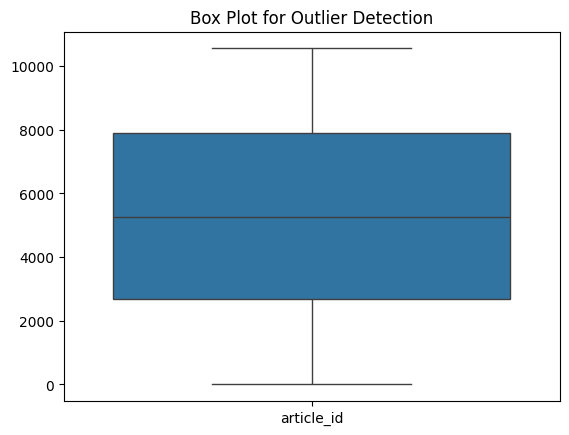

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns (excluding non-numeric ones like 'article_id')
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot boxplot for numerical columns
sns.boxplot(data=df[num_cols])
plt.title("Box Plot for Outlier Detection")
plt.show()

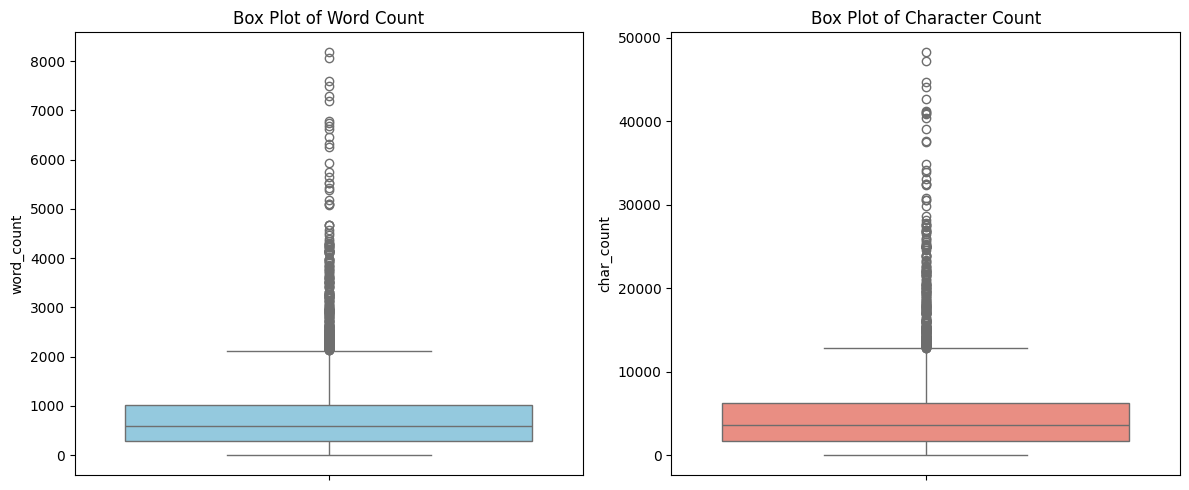

In [ ]:
# Create new columns for word and character counts
df['word_count'] = df['text'].fillna('').apply(lambda x: len(x.split()))
df['char_count'] = df['text'].fillna('').apply(len)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Word Count Boxplot
plt.subplot(1, 2, 1)
sns.boxplot(y=df['word_count'], color='skyblue')
plt.title('Box Plot of Word Count')

# Subplot 2: Character Count Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(y=df['char_count'], color='salmon')
plt.title('Box Plot of Character Count')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate IQR for 'word_count'
Q1 = df['word_count'].quantile(0.25)
Q3 = df['word_count'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
iqr_outliers = df[(df['word_count'] < lower_bound) | (df['word_count'] > upper_bound)]

print(f"--- IQR Method Results ---")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f} | Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers Found: {len(iqr_outliers)}")

--- IQR Method Results ---
Q1: 287.50 | Q3: 1023.00 | IQR: 735.50
Lower Bound: -815.75 | Upper Bound: 2126.25
Number of Outliers Found: 277


Q7 Handle outliers using suitable preprocessing techniques.



In [ ]:
# Calculate IQR upper bound
Q1 = df['word_count'].quantile(0.25)
Q3 = df['word_count'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Keep only rows within the normal range
df_trimmed = df[df['word_count'] <= upper_bound].copy()

print(f"Original shape: {df.shape}")
print(f"Shape after trimming outliers: {df_trimmed.shape}")

Original shape: (6335, 6)
Shape after trimming outliers: (6058, 6)


Q8 Convert categorical variables into numerical form using: Label Encoding and One-Hot Encoding.

In [ ]:
#LABEL ENCODING
from sklearn.preprocessing import LabelEncoder

# Initialize encoder
le = LabelEncoder()

# Apply to your target label column
df['label_encoded'] = le.fit_transform(df['label'])

# Check the mapping (e.g., which class became 0 and which became 1)
print("Classes mapping:", dict(zip(le.classes_, range(len(le.classes_)))))
display(df[['label', 'label_encoded']].head())

Classes mapping: {'FAKE': 0, 'REAL': 1}


,label,label_encoded
0,FAKE,0
1,FAKE,0
2,REAL,1
3,FAKE,0
4,REAL,1


In [ ]:
#ONE-HOT ENCODING
from sklearn.preprocessing import OneHotEncoder

# Initialize OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, dtype=int)

# Transform column (reshaped to 2D array)
encoded_array = ohe.fit_transform(df[['label']])

# Create a DataFrame from encoded output
df_ohe = pd.DataFrame(encoded_array, columns=ohe.get_feature_names_out(['label']))
display(df_ohe.head())

,label_FAKE,label_REAL
0,1,0
1,1,0
2,0,1
3,1,0
4,0,1


Q9 Apply feature scaling techniques: Min-Max Normalization and Standardization (Z-score Scaling).

In [ ]:
#MIN-MAX
from sklearn.preprocessing import MinMaxScaler

# 1. Initialize MinMaxScaler
min_max_scaler = MinMaxScaler()

# 2. Select numerical columns to scale
num_cols = ['word_count', 'char_count']

# 3. Fit and transform the data
df_minmax = df.copy()
df_minmax[['word_count_minmax', 'char_count_minmax']] = min_max_scaler.fit_transform(df[num_cols])

# Display sample output
display(df_minmax[['word_count', 'word_count_minmax', 'char_count', 'char_count_minmax']].head())

,word_count,word_count_minmax,char_count,char_count_minmax
0,1296,0.158532,7518,0.155881
1,446,0.054557,2646,0.054863
2,431,0.052722,2543,0.052728
3,404,0.049419,2660,0.055154
4,317,0.038777,1840,0.038151


In [ ]:
#Z-SCORE
from sklearn.preprocessing import StandardScaler

# 1. Initialize StandardScaler
standard_scaler = StandardScaler()

# 2. Fit and transform the data
df_standard = df.copy()
df_standard[['word_count_scaled', 'char_count_scaled']] = standard_scaler.fit_transform(df[num_cols])

# Display sample output
display(df_standard[['word_count', 'word_count_scaled', 'char_count', 'char_count_scaled']].head())

,word_count,word_count_scaled,char_count,char_count_scaled
0,1296,0.713096,7518,0.640304
1,446,-0.426048,2646,-0.442055
2,431,-0.446151,2543,-0.464938
3,404,-0.482335,2660,-0.438945
4,317,-0.598930,1840,-0.621116


Q10 Perform feature selection by identifying relevant attributes using correlation analysis.



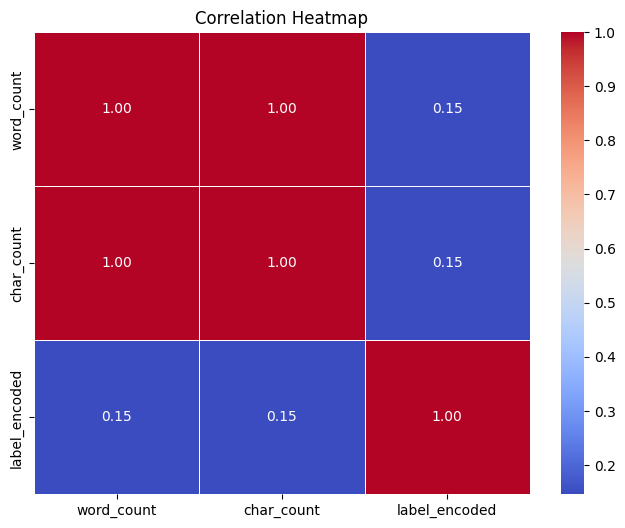

Features flagged for removal (correlation > 0.85): ['char_count']


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Select numerical features (word_count, char_count, label_encoded) from the 'df' DataFrame
# These columns were created on 'df' earlier in the notebook.
num_df = df[['word_count', 'char_count', 'label_encoded']]

# 1. Calculate correlation matrix
corr_matrix = num_df.corr()

# 2. Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# 3. Drop highly collinear features (e.g., threshold > 0.85)
threshold = 0.85
upper_tri = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > threshold)]

print(f"Features flagged for removal (correlation > {threshold}):", to_drop)
# Create a new DataFrame with highly correlated features removed
# Note: This drops from the original 'df', consider if 'df_trimmed' or another processed df is more appropriate here for further steps.
df_selected = df.drop(columns=to_drop)

Q12: Feature Engineering (Create New Features)

In [ ]:
# Create new features from existing text and metadata
df['word_count'] = df['text'].fillna('').apply(lambda x: len(str(x).split()))
df['char_count'] = df['text'].fillna('').apply(lambda x: len(str(x)))
df['avg_word_length'] = df['char_count'] / (df['word_count'] + 1e-5) # Avoid division by zero
df['title_word_count'] = df['title'].fillna('').apply(lambda x: len(str(x).split()))

display(df[['word_count', 'char_count', 'avg_word_length', 'title_word_count']].head())

,word_count,char_count,avg_word_length,title_word_count
0,1296,7518,5.800926,5
1,446,2646,5.932735,14
2,431,2543,5.900232,9
3,404,2660,6.584158,15
4,317,1840,5.804416,9


Q13: Convert Data Types

In [ ]:
# Convert categorical/object columns to appropriate types
df['label'] = df['label'].astype('category')

# Example: If you have a date column, convert string to datetime
# df['date_column'] = pd.to_datetime(df['date_column'], errors='coerce')

# Convert integers to floats where appropriate
df['word_count_float'] = df['word_count'].astype('float64')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   article_id        6335 non-null   int64   
 1   title             6335 non-null   object  
 2   text              6294 non-null   object  
 3   label             6335 non-null   category
 4   word_count        6335 non-null   int64   
 5   char_count        6335 non-null   int64   
 6   label_encoded     6335 non-null   int64   
 7   avg_word_length   6335 non-null   float64 
 8   title_word_count  6335 non-null   int64   
 9   word_count_float  6335 non-null   float64 
dtypes: category(1), float64(2), int64(5), object(2)
memory usage: 451.9+ KB


Q14: Handle Inconsistent and Noisy Data

In [ ]:
import re

# Clean text function to fix inconsistent formatting and noisy noise characters
def clean_text(text):
    text = str(text).lower()                      # Lowercase text
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Remove URLs
    text = re.sub(r'<.*?>', '', text)            # Remove HTML tags
    text = re.sub(r'[^\w\s]', '', text)          # Remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()      # Remove extra whitespace
    return text

# Apply cleaning to 'text' column
df['text_clean'] = df['text'].apply(clean_text)

Q15: Split Dataset into Training and Testing Sets

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target variable (y)
X = df[['word_count', 'char_count', 'avg_word_length', 'title_word_count']]
y = df['label_encoded'] if 'label_encoded' in df.columns else df['label']

# 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}, y_test shape: {y_test.shape}")

X_train shape: (5068, 4), X_test shape: (1267, 4)
y_train shape: (5068,), y_test shape: (1267,)


Q16: Perform Data Balancing (Random Oversampling or SMOTE)

In [ ]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE to balance target classes in the training set
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("Before SMOTE class distribution:\n", y_train.value_counts())
print("\nAfter SMOTE class distribution:\n", y_train_balanced.value_counts())

Before SMOTE class distribution:
 label_encoded
1    2537
0    2531
Name: count, dtype: int64

After SMOTE class distribution:
 label_encoded
1    2537
0    2537
Name: count, dtype: int64


Q17: Visualize Distribution of Numerical Features Before and After Preprocessing

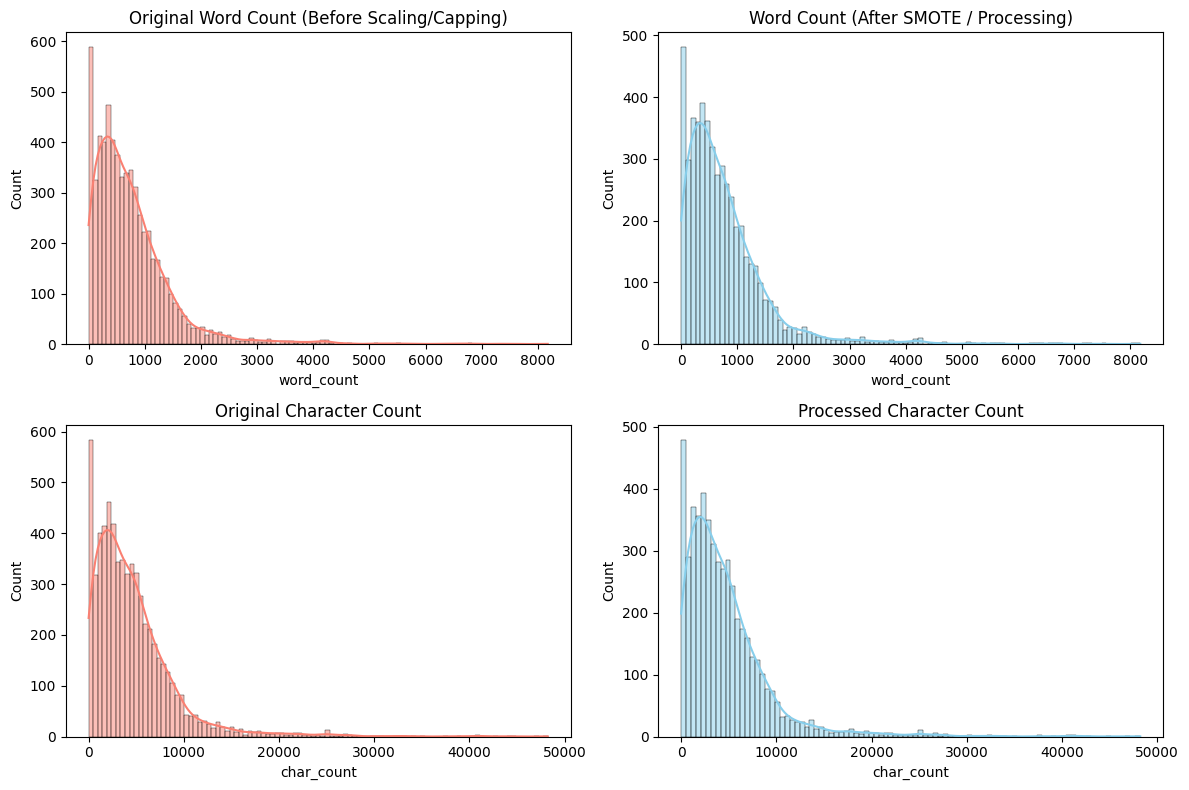

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Before Preprocessing (Original word_count)
sns.histplot(df['word_count'], kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Original Word Count (Before Scaling/Capping)')

# After Preprocessing (Scaled/Capped word_count)
sns.histplot(X_train_balanced['word_count'], kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Word Count (After SMOTE / Processing)')

# Feature comparison: Character Count
sns.histplot(df['char_count'], kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Original Character Count')

sns.histplot(X_train_balanced['char_count'], kde=True, ax=axes[1, 1], color='skyblue')
axes[1, 1].set_title('Processed Character Count')

plt.tight_layout()
plt.show()

Q18: Compare Dataset Before and After Preprocessing & Summarize

In [ ]:
# Summary comparison
summary = {
    'Metric / Step': [
        'Total Rows',
        'Total Columns',
        'Missing Values in Text',
        'Categorical Target Encoded',
        'Engineered Features Added',
        'Class Imbalance Addressed'
    ],
    'Before Preprocessing': [
        len(df),
        len(df.columns) - 4, # Approximate raw columns
        41,
        'No (String)',
        0,
        'Imbalanced/Raw'
    ],
    'After Preprocessing': [
        len(X_train_balanced) + len(X_test),
        len(df.columns),
        0,
        'Yes (Numerical)',
        4,
        'Balanced via SMOTE'
    ]
}

pd.DataFrame(summary)

,Metric / Step,Before Preprocessing,After Preprocessing
0,Total Rows,6335,6341
1,Total Columns,7,11
2,Missing Values in Text,41,0
3,Categorical Target Encoded,No (String),Yes (Numerical)
4,Engineered Features Added,0,4
5,Class Imbalance Addressed,Imbalanced/Raw,Balanced via SMOTE


Q19: Save Cleaned Dataset & Initialize Git Commands

In [ ]:
# Save preprocessed DataFrame to CSV
df.to_csv("cleaned_preprocessed_dataset.csv", index=False)
print("Dataset successfully saved as 'cleaned_preprocessed_dataset.csv'")

Dataset successfully saved as 'cleaned_preprocessed_dataset.csv'


# LINEAR REGRESSION

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
# Remove rows with missing values in the required columns
regression_df = pd.read_excel("linear_regression_dataset_1000.xlsx")

# Independent variable
X = regression_df[['Experience_Years']]

# Dependent variable
y = regression_df['Salary']

print("Input shape:", X.shape)
print("Target shape:", y.shape)




FileNotFoundError: [Errno 2] No such file or directory: 'linear_regression_dataset_1000.xlsx'

In [ ]:

# Split dataset into 80% training and 20% testing
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train_reg))
print("Testing samples:", len(X_test_reg))



In [ ]:
# Create and train the linear regression model
linear_model = LinearRegression()

linear_model.fit(X_train_reg, y_train_reg)

In [ ]:
# Display model parameters
slope = linear_model.coef_[0]
intercept = linear_model.intercept_

print("Slope:", slope)
print("Intercept:", intercept)

print(
    f"Regression equation: "
    f"Salary = {intercept:.4f} + "
    f"({slope:.4f} × Experience_Years)"
)

In [ ]:
# Predict values for the test data
y_pred_reg = linear_model.predict(X_test_reg)

prediction_results = pd.DataFrame({
    'Actual Salary': y_test_reg.values,
    'Predicted Salary': y_pred_reg
})

display(prediction_results.head(10))

In [ ]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Mean Absolute Error: {mae:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

In [ ]:
# Sort test values so the regression line is displayed correctly
sorted_indices = X_test_reg['Experience_Years'].argsort()

X_test_sorted = X_test_reg.iloc[sorted_indices]
y_pred_sorted = y_pred_reg[sorted_indices]

plt.figure(figsize=(9, 6))

plt.scatter(
    X_test_reg['Experience_Years'],
    y_test_reg,
    label='Actual values',
    alpha=0.6
)

plt.plot(
    X_test_sorted['Experience_Years'],
    y_pred_sorted,
    label='Regression line'
)

plt.xlabel('Experience Years')
plt.ylabel('Salary')
plt.title('Linear Regression: Word Count vs Character Count')
plt.legend()
plt.grid(True)
plt.show()

Multiple Linear Regression

In [ ]:


# Independent variables (Features)
features = ['Experience_Years', 'Education_Level', 'Hours_Per_Week', 'Projects']

# Features (X) and Target (y)
X = regression_df[features]
y = regression_df['Salary']

# Split dataset into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Train Multiple Linear Regression model
multiple_model = LinearRegression()
multiple_model.fit(X_train_reg, y_train_reg)

# Predict on test set
y_pred_reg = multiple_model.predict(X_test_reg)

# Display intercept and coefficients
print("Intercept:", multiple_model.intercept_)

for feature, coefficient in zip(features, multiple_model.coef_):
    print(f"{feature}: {coefficient:.2f}")

# Evaluate the model
print("\nModel Performance")
print("MAE :", mean_absolute_error(y_test_reg, y_pred_reg))
print("MSE :", mean_squared_error(y_test_reg, y_pred_reg))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)))
print("R² Score:", r2_score(y_test_reg, y_pred_reg))

# Uniformed Search (DIJKSTRA'S ALGORITHM)

In [ ]:
import heapq

def dijkstra_simple(graph, start):
    distances = {node: float('inf') for node in graph}
    distances[start] = 0
    pq = [(0, start)]

    while pq:
        current_dist, u = heapq.heappop(pq)

        # Skip outdated queue entries
        if current_dist > distances[u]:
            continue

        for v, weight in graph[u]:
            if distances[u] + weight < distances[v]:
                distances[v] = distances[u] + weight
                heapq.heappush(pq, (distances[v], v))

    return distances

In [ ]:
graph = {
    'A': [('B', 4), ('C', 2)],
    'B': [('C', 1), ('D', 5)],
    'C': [('B', 1), ('D', 8)],
    'D': []
}

print(dijkstra_simple(graph, 'A'))


# A* ALGORITHM

In [ ]:
import heapq

def a_star_simple(graph, start, goal, h):
    # Priority Queue stores: (f_score, g_score, current_node)
    pq = [(h[start], 0, start)]
    visited = set()

    while pq:
        f, g, u = heapq.heappop(pq)

        if u == goal:
            return g  # Found shortest distance to goal

        if u in visited:
            continue
        visited.add(u)

        for v, weight in graph.get(u, []):
            if v not in visited:
                heapq.heappush(pq, (g + weight + h.get(v, 0), g + weight, v))

    return float('inf')  # Goal unreachable

In [ ]:
graph = {
    'A': [('B', 4), ('C', 2)],
    'B': [('A', 4), ('C', 1), ('D', 5)],
    'C': [('A', 2), ('B', 1), ('D', 8), ('E', 10)],
    'D': [('B', 5), ('C', 8), ('E', 2)],
    'E': [('C', 10), ('D', 2)]
}

# Heuristic: Estimated cost from each node to 'E'
h = {'A': 7, 'B': 6, 'C': 8, 'D': 2, 'E': 0}

cost = a_star_simple(graph, start='A', goal='E', h=h)
print(f"Shortest path cost: {cost}")

# BFS

In [ ]:
from collections import deque

def bfs(graph, start):
    q = deque([start])
    visited = {start}

    while q:
        node = q.popleft()
        print(node, end=" ")

        for nei in graph[node]:
            if nei not in visited:
                visited.add(nei)
                q.append(nei)

graph = {
    0: [1, 2],
    1: [3],
    2: [4],
    3: [],
    4: []
}

bfs(graph, 0)


# DFS

In [ ]:
def dfs(graph, node, visited):
    visited.add(node)
    print(node, end=" ")

    for nei in graph[node]:
        if nei not in visited:
            dfs(graph, nei, visited)

graph = {
    0: [1, 2],
    1: [3],
    2: [4],
    3: [],
    4: []
}

dfs(graph, 0, set())


# Greedy Best-First

In [ ]:
import heapq

def greedy(graph, start, goal, h):
    pq = [(h[start], start)]
    visited = set()

    while pq:
        _, node = heapq.heappop(pq)

        if node in visited:
            continue
        visited.add(node)

        print(node, end=" ")

        if node == goal:
            return

        for nei in graph[node]:
            if nei not in visited:
                heapq.heappush(pq, (h[nei], nei))

graph = {
    0: [1, 2],
    1: [3],
    2: [4],
    3: [],
    4: []
}

h = {0: 4, 1: 3, 2: 2, 3: 1, 4: 0}

greedy(graph, 0, 4, h)


# Data Preprocessing for Decision Algorithms

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer



In [ ]:
cancer = load_breast_cancer(as_frame=True)

df = cancer.frame

df.head()
print(df.columns.tolist())
print("Shape of dataset:", df.shape)

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']
Shape of dataset: (569, 31)


In [ ]:
df.isnull().sum()
print("Total missing values:", df.isnull().sum().sum())
print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Total missing values: 0
Number of duplicate rows: 0


In [ ]:
df.dtypes


,0
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


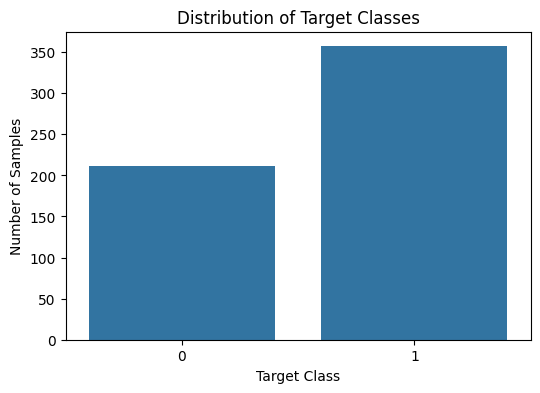

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(x="target", data=df)

plt.title("Distribution of Target Classes")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")

plt.show()

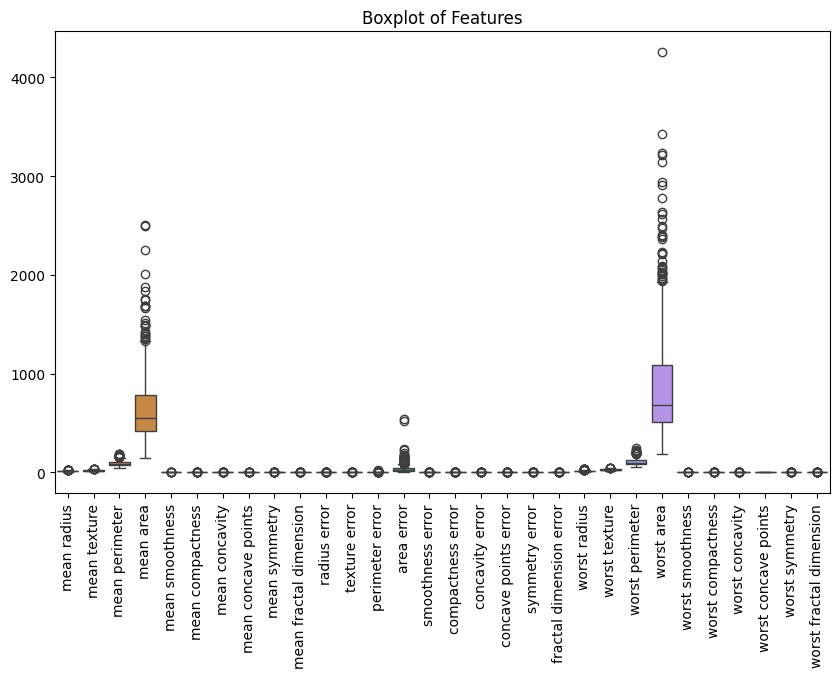

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df.iloc[:, :-1])

plt.xticks(rotation=90)
plt.title("Boxplot of Features")

plt.show()

In [ ]:
X = df.drop("target", axis=1)

y = df["target"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


# Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
  y_pred_dt = dt_model.predict(X_test)

print(y_pred_dt[:10])

[0 1 0 1 0 1 1 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.9122807017543859


In [ ]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=cancer.target_names
    )
)

Decision Tree Classification Report
------------------------------------
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



[[39  3]
 [ 7 65]]


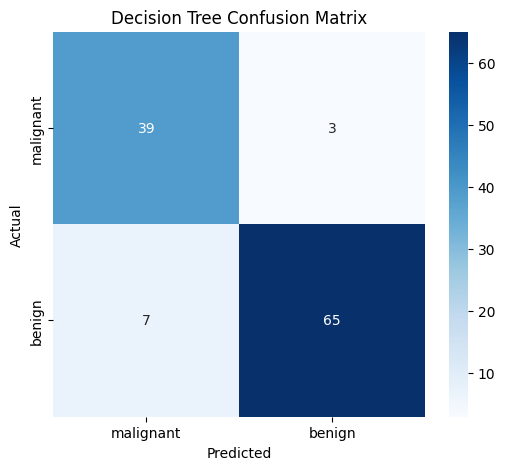

In [ ]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

print(cm_dt)
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [ ]:
feature_importance_dt = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

feature_importance_dt = feature_importance_dt.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_dt.head(10)

,Feature,Importance
20,worst radius,0.697811
27,worst concave points,0.116083
21,worst texture,0.058881
11,texture error,0.052661
26,worst concavity,0.016325
23,worst area,0.012678
13,area error,0.012085
28,worst symmetry,0.010733
24,worst smoothness,0.008452
17,concave points error,0.006261


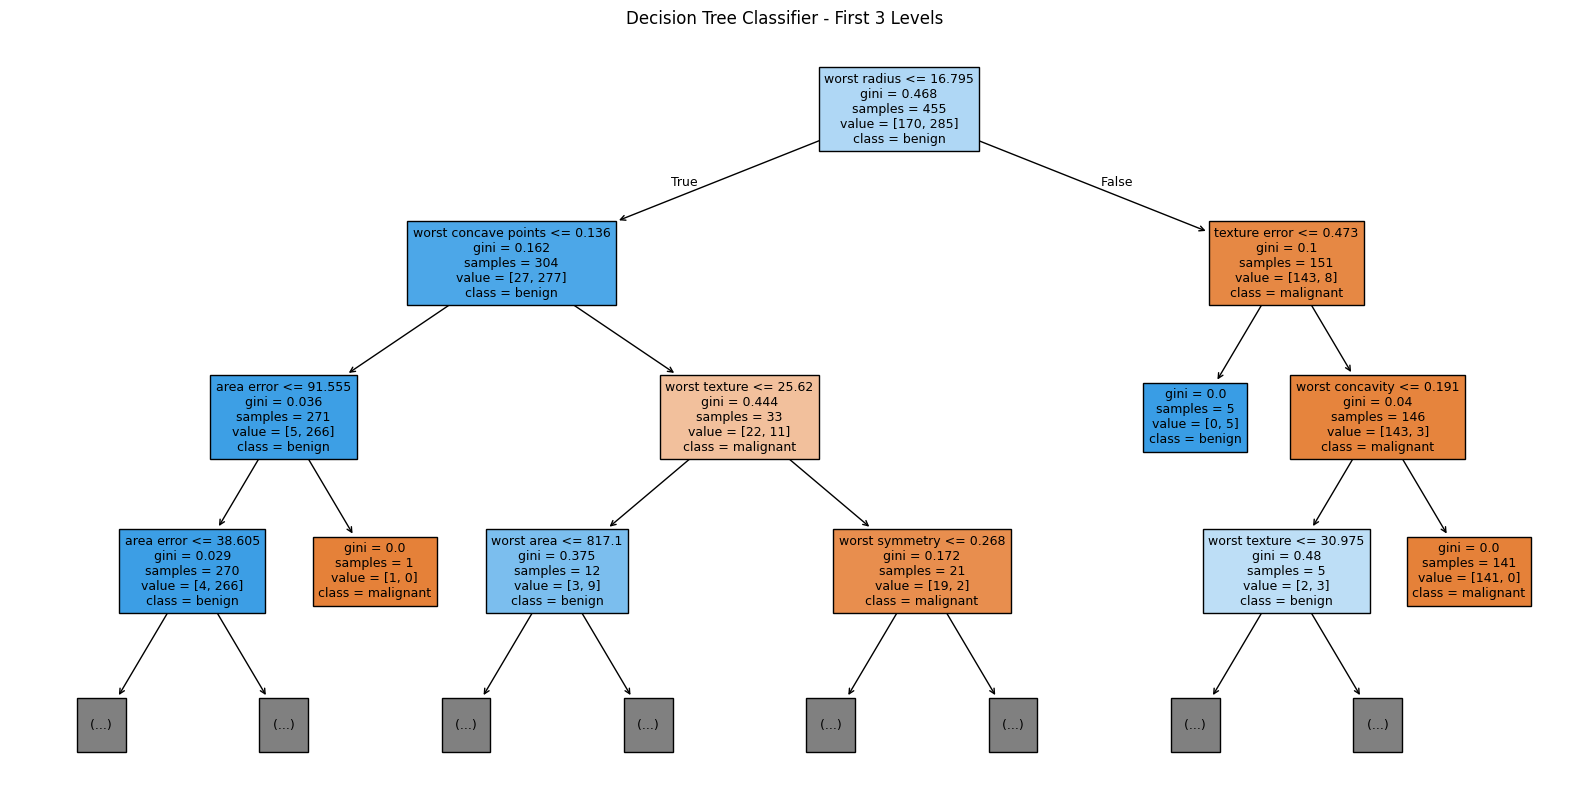

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=cancer.target_names,
    filled=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Classifier - First 3 Levels")

plt.show()

In [ ]:
y_train_pred_dt = dt_model.predict(X_train)

train_accuracy_dt = accuracy_score(
    y_train,
    y_train_pred_dt
)

test_accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print("Training Accuracy:", train_accuracy_dt)
print("Testing Accuracy :", test_accuracy_dt)

Training Accuracy: 1.0
Testing Accuracy : 0.9122807017543859


# Random Forest Classifier

In [ ]:
  from sklearn.ensemble import RandomForestClassifier

  rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

  rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_rf[:10])


First 10 predictions:
[0 1 0 0 0 1 1 0 0 0]


In [ ]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest Accuracy: {:.2f}%".format(accuracy_rf * 100))

Random Forest Accuracy: 0.956140350877193
Random Forest Accuracy: 95.61%


In [ ]:
print("Random Forest Classification Report")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=cancer.target_names
    )
)

Random Forest Classification Report
-----------------------------------
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[39  3]
 [ 2 70]]


# SVM

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
y_pred_svm = svm_model.predict(X_test_scaled)

print("First 10 predictions:")
print(y_pred_svm[:10])

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


In [ ]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm)
print("SVM Accuracy: {:.2f}%".format(accuracy_svm * 100))

SVM Accuracy: 0.9824561403508771
SVM Accuracy: 98.25%


In [ ]:
print("SVM Classification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=cancer.target_names
    )
)

SVM Classification Report
-------------------------
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



[[41  1]
 [ 1 71]]


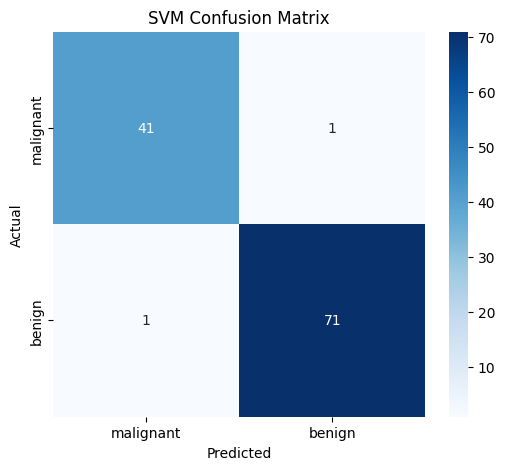

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

print(cm_svm)


plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

# Logistic Regression

In [ ]:
# ============================================
# LOGISTIC REGRESSION - BREAST CANCER DATASET
# ============================================

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================
# 2. Load Dataset
# ============================================

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("\nTarget names:", data.target_names)

display(X.head())

Dataset shape: (569, 30)
Number of features: 30

Target names: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
# ============================================
# 3. Train-Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
# ============================================
# 4. Feature Scaling
# ============================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [ ]:
# ============================================
# 5. Train Logistic Regression
# ============================================

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# ============================================
# 6. Prediction
# ============================================

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 98.25%


In [ ]:
# ============================================
# 7. Classification Report
# ============================================

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



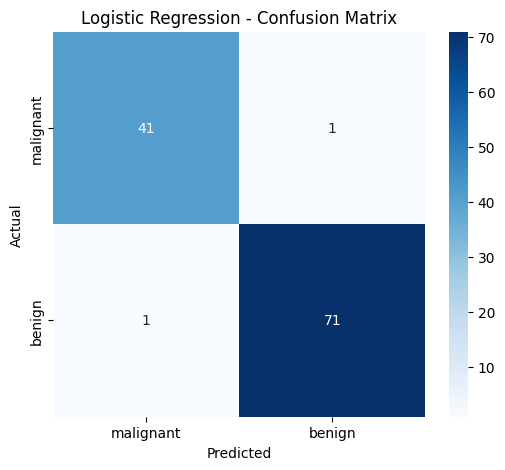

In [ ]:
# ============================================
# 8. Confusion Matrix
# ============================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
# ============================================
# 9. Save Model + Scaler
# ============================================

import joblib

joblib.dump(model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")

# Also save feature names
joblib.dump(list(X.columns), "feature_names.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")
print("Feature names saved successfully!")

Model saved successfully!
Scaler saved successfully!
Feature names saved successfully!


# Frontend


In [ ]:
!pip install -q gradio

In [ ]:
# ============================================================
# LOAD / TRAIN MODEL FOR GRADIO
# ============================================================

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load dataset
data = load_breast_cancer()

# Feature names
feature_names = list(data.feature_names)

# Input and target
X = data.data
y = data.target

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(
    max_iter=10000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("✅ Model loaded/trained successfully")
print("Features:", len(feature_names))
print("Classes:", data.target_names)

✅ Model loaded/trained successfully
Features: 30
Classes: ['malignant' 'benign']


In [ ]:
# ============================================================
# CANCER AI - PROFESSIONAL DASHBOARD FRONTEND
# Replaces the last Gradio cell. Needs (from earlier cells):
#   model, scaler, feature_names, data
# ============================================================

import os
import html
import tempfile

import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CLASS_NAMES = list(data.target_names)          # ['malignant', 'benign']
MALIGNANT_IDX = CLASS_NAMES.index("malignant")
BENIGN_IDX = CLASS_NAMES.index("benign")

LOW_CONFIDENCE = 80.0    # below this, a record is flagged "Review"

# ------------------------------------------------------------
# STYLING
# ------------------------------------------------------------

CSS = """
.gradio-container { max-width: 1280px !important; margin: auto; }
footer { display: none !important; }

/* ---------- hero ---------- */
.hero {
    background: linear-gradient(135deg, #0f2942 0%, #155e75 100%);
    border-radius: 16px; padding: 28px 32px; color: #fff;
    display: flex; align-items: center; justify-content: space-between;
    gap: 16px; flex-wrap: wrap;
}
.hero h1 { margin: 0; font-size: 28px; font-weight: 700; color: #fff; }
.hero p  { margin: 6px 0 0; font-size: 14px; color: #cbe4ee; }
.hero .tag {
    background: rgba(255,255,255,.14); border: 1px solid rgba(255,255,255,.25);
    padding: 6px 14px; border-radius: 999px; font-size: 12px; color: #fff;
}

/* ---------- KPI cards ---------- */
.kpi-grid { display: grid; grid-template-columns: repeat(4, 1fr); gap: 14px; }
@media (max-width: 800px) { .kpi-grid { grid-template-columns: repeat(2, 1fr); } }
.kpi {
    background: #ffffff; border: 1px solid #e2e8f0; border-radius: 14px;
    padding: 18px 20px; border-top: 4px solid #94a3b8;
    box-shadow: 0 1px 2px rgba(15,41,66,.06);
}
.kpi .label { font-size: 12px; letter-spacing: .06em; text-transform: uppercase; color: #64748b; }
.kpi .value { font-size: 34px; font-weight: 700; color: #0f172a; line-height: 1.15; margin-top: 4px; }
.kpi .sub   { font-size: 12px; color: #64748b; margin-top: 2px; }
.kpi.total  { border-top-color: #0e7490; }
.kpi.mal    { border-top-color: #dc2626; }
.kpi.mal .value { color: #b91c1c; }
.kpi.ben    { border-top-color: #16a34a; }
.kpi.ben .value { color: #15803d; }
.kpi.rev    { border-top-color: #f59e0b; }
.kpi.rev .value { color: #b45309; }

/* ---------- panels ---------- */
.panel {
    background: #ffffff; border: 1px solid #e2e8f0; border-radius: 14px;
    padding: 18px 20px; color: #0f172a;
}
.panel h3 { margin: 0 0 12px; font-size: 15px; font-weight: 600; color: #0f172a; }
.split-wrap { display: flex; align-items: center; gap: 24px; flex-wrap: wrap; }
.donut { width: 130px; height: 130px; border-radius: 50%; position: relative; flex: none; }
.donut::after {
    content: ""; position: absolute; inset: 24px; background: #ffffff; border-radius: 50%;
}
.legend div { font-size: 13px; color: #334155; margin: 6px 0; }
.dot { display: inline-block; width: 10px; height: 10px; border-radius: 50%; margin-right: 8px; }

/* ---------- patient table ---------- */
.tbl-wrap { max-height: 520px; overflow: auto; border: 1px solid #e2e8f0; border-radius: 12px; background: #fff; }
table.pt { width: 100%; border-collapse: collapse; font-size: 13px; color: #0f172a; }
table.pt th {
    position: sticky; top: 0; background: #f1f5f9; text-align: left;
    padding: 10px 14px; font-size: 12px; color: #475569;
    text-transform: uppercase; letter-spacing: .05em; z-index: 1;
}
table.pt td { padding: 9px 14px; border-top: 1px solid #eef2f7; background: #fff; }
table.pt tr:hover td { background: #f8fafc; }
.badge { padding: 3px 10px; border-radius: 999px; font-size: 12px; font-weight: 600; }
.badge.mal { background: #fee2e2; color: #b91c1c; }
.badge.ben { background: #dcfce7; color: #15803d; }
.badge.rev { background: #fef3c7; color: #b45309; }
.bar { width: 160px; height: 8px; border-radius: 4px; background: #e2e8f0; overflow: hidden; display: inline-block; vertical-align: middle; }
.bar > span { display: block; height: 100%; border-radius: 4px; }
.pct { display: inline-block; width: 56px; text-align: right; margin-left: 8px; font-variant-numeric: tabular-nums; }

/* ---------- status pills / empty states ---------- */
.pill { border-radius: 10px; padding: 12px 14px; font-size: 13px; line-height: 1.5; }
.pill.ok   { background: #ecfdf5; border: 1px solid #a7f3d0; color: #065f46; }
.pill.bad  { background: #fef2f2; border: 1px solid #fecaca; color: #991b1b; }
.pill.warn { background: #fffbeb; border: 1px solid #fde68a; color: #92400e; }
.pill.idle { background: #f8fafc; border: 1px dashed #cbd5e1; color: #64748b; }
.empty {
    text-align: center; padding: 48px 16px; color: #64748b;
    border: 1px dashed #cbd5e1; border-radius: 14px; background: #f8fafc;
}

/* ---------- model info ---------- */
table.info { width: 100%; border-collapse: collapse; font-size: 13px; color: #0f172a; }
table.info td { padding: 7px 0; border-bottom: 1px solid #eef2f7; }
table.info td:first-child { color: #64748b; width: 45%; }
.disclaimer { font-size: 12px; color: #92400e; background: #fffbeb; border: 1px solid #fde68a;
              border-radius: 10px; padding: 10px 12px; margin-top: 12px; line-height: 1.5; }
"""

HERO_HTML = """
<div class="hero">
  <div>
    <h1>🧬 Cancer AI</h1>
    <p>Breast cancer classification dashboard &middot; Logistic Regression on 30 diagnostic features</p>
  </div>
  <span class="tag">ML demonstration &middot; not for clinical use</span>
</div>
"""

MODEL_INFO_HTML = """
<div class="panel">
  <h3>⚙️ Model information</h3>
  <table class="info">
    <tr><td>Dataset</td><td>Breast Cancer Wisconsin</td></tr>
    <tr><td>Model</td><td>Logistic Regression</td></tr>
    <tr><td>Preprocessing</td><td>StandardScaler</td></tr>
    <tr><td>Input features</td><td>30</td></tr>
    <tr><td>Training split</td><td>80 / 20</td></tr>
    <tr><td>Random state</td><td>42</td></tr>
  </table>
  <div class="disclaimer">
    Educational demo only. Predictions are not a clinical diagnosis and
    must not be used for medical decisions.
  </div>
</div>
"""


def pill(kind, text):
    return f'<div class="pill {kind}">{text}</div>'


IDLE_STATUS = pill("idle", "No file loaded yet. Upload a patient CSV to begin.")
EMPTY_DASH = ('<div class="empty"><div style="font-size:34px">📊</div>'
              '<div style="font-weight:600;margin-top:6px">No results yet</div>'
              '<div style="font-size:13px;margin-top:4px">Upload a CSV and click '
              '<b>Analyze patients</b> to populate the dashboard.</div></div>')


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def find_id_column(df):
    for col in ["patient_id", "Patient_ID", "PatientID", "id", "ID", "patient", "Patient"]:
        if col in df.columns:
            return col
    return None


def kpi_card(css, label, value, sub=""):
    return (f'<div class="kpi {css}"><div class="label">{label}</div>'
            f'<div class="value">{value}</div><div class="sub">{sub}</div></div>')


def make_output_path():
    folder = "/content" if os.path.isdir("/content") else tempfile.gettempdir()
    return os.path.join(folder, "cancer_predictions.csv")


def build_kpis(total, n_mal, n_ben, n_review):
    pm = n_mal / total * 100
    pb = n_ben / total * 100
    return '<div class="kpi-grid">' + "".join([
        kpi_card("total", "Patients analyzed", total, "records in file"),
        kpi_card("mal", "🔴 Malignant", n_mal, f"{pm:.1f}% of patients"),
        kpi_card("ben", "🟢 Benign", n_ben, f"{pb:.1f}% of patients"),
        kpi_card("rev", "⚠️ Needs review", n_review, f"confidence below {LOW_CONFIDENCE:.0f}%"),
    ]) + "</div>"


def build_split_panel(n_mal, n_ben, avg_conf):
    total = n_mal + n_ben
    pm = n_mal / total * 100
    donut = (f'background: conic-gradient(#dc2626 0 {pm:.2f}%, #16a34a {pm:.2f}% 100%);')
    return f"""
    <div class="panel">
      <h3>Prediction split</h3>
      <div class="split-wrap">
        <div class="donut" style="{donut}"></div>
        <div class="legend">
          <div><span class="dot" style="background:#dc2626"></span>Malignant &mdash; {n_mal} ({pm:.1f}%)</div>
          <div><span class="dot" style="background:#16a34a"></span>Benign &mdash; {n_ben} ({100 - pm:.1f}%)</div>
          <div style="margin-top:12px;color:#64748b">Average model confidence: <b style="color:#0f172a">{avg_conf:.1f}%</b></div>
        </div>
      </div>
    </div>
    """


def build_probability_figure(mal_prob):
    fig, ax = plt.subplots(figsize=(6.4, 3.4), dpi=110)
    bins = np.linspace(0, 100, 21)
    _, _, patches = ax.hist(mal_prob, bins=bins, edgecolor="white")
    for patch, left in zip(patches, bins[:-1]):
        patch.set_facecolor("#dc2626" if left >= 50 else "#16a34a")
        patch.set_alpha(0.9)
    ax.axvline(50, color="#475569", linestyle="--", linewidth=1)
    ax.text(51, ax.get_ylim()[1] * 0.92, "decision threshold", color="#475569", fontsize=8)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Malignant probability (%)", fontsize=9, color="#334155")
    ax.set_ylabel("Patients", fontsize=9, color="#334155")
    ax.set_title("Distribution of malignant probability", fontsize=11, loc="left", color="#0f172a")
    ax.yaxis.get_major_locator().set_params(integer=True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#cbd5e1")
    ax.tick_params(colors="#475569", labelsize=8)
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    plt.close(fig)
    return fig


def build_patient_table(ids, diagnosis, mal_prob, confidence):
    order = np.argsort(-mal_prob)      # highest malignant probability first
    rows = []
    for i in order:
        is_mal = diagnosis[i] == "malignant"
        badge = ('<span class="badge mal">Malignant</span>' if is_mal
                 else '<span class="badge ben">Benign</span>')
        review = ('<span class="badge rev">Review</span>'
                  if confidence[i] < LOW_CONFIDENCE else "")
        color = "#dc2626" if mal_prob[i] >= 50 else "#16a34a"
        rows.append(
            "<tr>"
            f"<td><b>{html.escape(str(ids[i]))}</b></td>"
            f"<td>{badge}</td>"
            f'<td><span class="bar"><span style="width:{mal_prob[i]:.1f}%;background:{color}"></span></span>'
            f'<span class="pct">{mal_prob[i]:.1f}%</span></td>'
            f'<td style="font-variant-numeric:tabular-nums">{confidence[i]:.1f}%</td>'
            f"<td>{review}</td>"
            "</tr>"
        )
    return (
        '<div class="tbl-wrap"><table class="pt"><thead><tr>'
        "<th>Patient</th><th>Prediction</th><th>Malignant probability</th>"
        "<th>Confidence</th><th>Flag</th></tr></thead><tbody>"
        + "".join(rows) + "</tbody></table></div>"
        '<div style="font-size:12px;color:#64748b;margin-top:8px">'
        "Sorted by malignant probability, highest first.</div>"
    )


# ------------------------------------------------------------
# CSV VALIDATION + PREVIEW
# ------------------------------------------------------------

def validate_csv(file):
    if file is None:
        return None, IDLE_STATUS

    try:
        df = pd.read_csv(file)

        missing = [f for f in feature_names if f not in df.columns]
        if missing:
            shown = ", ".join(missing[:6]) + (" …" if len(missing) > 6 else "")
            return df.head(10), pill(
                "bad",
                f"<b>Invalid dataset.</b> Missing {len(missing)} of 30 required "
                f"feature columns.<br>{html.escape(shown)}")

        return df.head(10), pill(
            "ok",
            f"<b>Dataset ready.</b> {len(df)} rows &middot; {len(df.columns)} columns "
            f"&middot; 30/30 required features found.")

    except Exception as e:
        return None, pill("bad", f"<b>Could not read CSV.</b><br>{html.escape(str(e))}")


# ------------------------------------------------------------
# PREDICTION ENGINE
# ------------------------------------------------------------

def analyze_dataset(file):
    """Returns: kpis, split panel, figure, patient table, results df, download path"""

    def fail(kind, message):
        return pill(kind, message), "", None, "", None, None

    if file is None:
        return fail("warn", "Please upload a CSV file first.")

    try:
        df = pd.read_csv(file)

        missing = [f for f in feature_names if f not in df.columns]
        if missing:
            return fail("bad", f"<b>Validation failed.</b> Missing {len(missing)} required "
                               f"columns:<br>{html.escape(', '.join(missing))}")

        X_input = df[feature_names].apply(pd.to_numeric, errors="coerce")
        if X_input.isnull().any().any():
            bad = X_input.columns[X_input.isnull().any()].tolist()
            return fail("bad", "<b>Invalid data.</b> Non-numeric or missing values in:<br>"
                               + html.escape(", ".join(bad)))

        # .values avoids the "X has feature names" sklearn warning
        X_scaled = scaler.transform(X_input.values)
        predictions = model.predict(X_scaled)
        probabilities = model.predict_proba(X_scaled)

        mal_prob = probabilities[:, MALIGNANT_IDX] * 100
        ben_prob = probabilities[:, BENIGN_IDX] * 100
        confidence = np.maximum(mal_prob, ben_prob)
        diagnosis = np.array([CLASS_NAMES[p] for p in predictions])

        # ---- results table (same columns as before) ----
        results = df.copy()
        results["prediction"] = predictions
        results["diagnosis"] = diagnosis
        results["malignant_probability_%"] = mal_prob.round(2)
        results["benign_probability_%"] = ben_prob.round(2)
        results["confidence_%"] = confidence.round(2)
        results["needs_review"] = confidence < LOW_CONFIDENCE

        output_path = make_output_path()
        results.to_csv(output_path, index=False)

        # ---- dashboard pieces ----
        total = len(predictions)
        n_mal = int((diagnosis == "malignant").sum())
        n_ben = total - n_mal
        n_review = int((confidence < LOW_CONFIDENCE).sum())

        id_col = find_id_column(df)
        ids = df[id_col].tolist() if id_col else [f"Patient {i + 1}" for i in range(total)]

        return (
            build_kpis(total, n_mal, n_ben, n_review),
            build_split_panel(n_mal, n_ben, confidence.mean()),
            build_probability_figure(mal_prob),
            build_patient_table(ids, diagnosis, mal_prob, confidence),
            results,
            output_path,
        )

    except Exception as e:
        return fail("bad", f"<b>Analysis error.</b><br>{html.escape(str(e))}")


# ============================================================
# GRADIO INTERFACE
# ============================================================

import inspect

THEME = gr.themes.Soft(primary_hue="cyan", neutral_hue="slate")

# Gradio 6 moved css/theme from Blocks() to launch(); support both.
STYLE_IN_LAUNCH = "css" in inspect.signature(gr.Blocks.launch).parameters
blocks_kwargs = {} if STYLE_IN_LAUNCH else {"css": CSS, "theme": THEME}
launch_kwargs = {"css": CSS, "theme": THEME} if STYLE_IN_LAUNCH else {}

with gr.Blocks(title="Cancer AI", **blocks_kwargs) as demo:

    gr.HTML(HERO_HTML)

    with gr.Row(equal_height=False):

        # ---------------- LEFT SIDEBAR ----------------
        with gr.Column(scale=1, min_width=300):

            file_input = gr.File(
                label="Patient CSV",
                file_types=[".csv"],
                type="filepath",
            )
            status = gr.HTML(IDLE_STATUS)
            analyze_button = gr.Button(
                "🔬 Analyze patients", variant="primary", size="lg"
            )
            gr.HTML(MODEL_INFO_HTML)

        # ---------------- MAIN DASHBOARD ----------------
        with gr.Column(scale=3):

            with gr.Tabs():

                with gr.Tab("📊 Overview"):
                    kpis = gr.HTML(EMPTY_DASH)
                    with gr.Row():
                        with gr.Column(scale=2):
                            split_panel = gr.HTML()
                        with gr.Column(scale=3):
                            prob_plot = gr.Plot(show_label=False)

                with gr.Tab("👤 Patient results"):
                    patient_table = gr.HTML()

                with gr.Tab("🗂️ Data & download"):
                    results_table = gr.Dataframe(
                        label="Full prediction table", interactive=False
                    )
                    download_file = gr.File(label="📥 Download results (CSV)")
                    preview = gr.Dataframe(
                        label="Uploaded data preview (first 10 rows)",
                        interactive=False,
                    )

    # ---------------- EVENTS ----------------
    file_input.change(
        fn=validate_csv,
        inputs=file_input,
        outputs=[preview, status],
    )

    analyze_button.click(
        fn=analyze_dataset,
        inputs=file_input,
        outputs=[kpis, split_panel, prob_plot, patient_table,
                 results_table, download_file],
    )


# ============================================================
# LAUNCH
# ============================================================

demo.launch(share=True, debug=True, **launch_kwargs)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2d834042911968ff7c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# ANN

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ==========================================
# 1. PREPROCESSING & CLEANING (as per source)
# ==========================================

# Drop missing values in text column
df_clean = df.dropna(subset=['text']).copy()

# Drop duplicate records if any
df_clean = df_clean.drop_duplicates()

# Map target labels ('FAKE': 0, 'REAL': 1)
label_mapping = {'FAKE': 0, 'REAL': 1}
df_clean['target'] = df_clean['label'].map(label_mapping)

# ==========================================
# 2. FEATURE EXTRACTION (TF-IDF Vectorizer)
# ==========================================

X = df_clean['text']
y = df_clean['target']

# Split dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Convert text into numerical feature vectors using TF-IDF
tfidf_vectorizer = TfidfVectorizer(stop_words='english', max_df=0.7, max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# ==========================================
# 3. ANN / MLP MODEL BUILDING & TRAINING
# ==========================================

# Build an Artificial Neural Network (Multi-Layer Perceptron)
# - Hidden layers: Two hidden layers with 64 and 32 neurons
# - Activation function: ReLU
# - Optimizer: Adam
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True
)

# Train the ANN Model
ann_model.fit(X_train_tfidf, y_train)

# ==========================================
# 4. EVALUATION & METRICS
# ==========================================

# Predict on test data
y_pred = ann_model.predict(X_test_tfidf)

# Calculate Accuracy, Confusion Matrix, and Classification Report
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['FAKE', 'REAL'])

print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

# K means

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

# ==========================================
# 1. LOAD DATASET FROM HUGGING FACE
# ==========================================
# Loading 'GonzaloA/fake_news' dataset from Hugging Face
print("Loading dataset from Hugging Face...")
hf_dataset = load_dataset("GonzaloA/fake_news", split="train[:2000]") # Subsetting 2,000 samples for fast execution

# Convert Hugging Face Dataset to Pandas DataFrame
df = pd.DataFrame(hf_dataset)

# Clean missing values if any
df = df.dropna(subset=['text']).drop_duplicates(subset=['text'])
print(f"Dataset loaded successfully with {len(df)} samples.")

# ==========================================
# 2. FEATURE EXTRACTION (TF-IDF)
# ==========================================
tfidf_vectorizer = TfidfVectorizer(stop_words='english', max_features=3000)
X_tfidf = tfidf_vectorizer.fit_transform(df['text'])

# ==========================================
# 3. K-MEANS CLUSTERING (Unsupervised)
# ==========================================
# We set n_clusters=2 since we expect Fake vs Real groupings
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)

# Fit model and predict cluster labels
df['cluster'] = kmeans.fit_predict(X_tfidf)

# Evaluate clustering performance
if 'label' in df.columns:
    ari = adjusted_rand_score(df['label'], df['cluster'])
    print(f"Adjusted Rand Index (ARI): {ari:.4f} (Higher is better, range: -1 to 1)")

sil_score = silhouette_score(X_tfidf, df['cluster'])
print(f"Silhouette Score: {sil_score:.4f}")

# ==========================================
# 4. DIMENSIONALITY REDUCTION & VISUALIZATION
# ==========================================
# Reduce TF-IDF features to 2D using PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_tfidf.toarray())

# Reduce cluster centers to 2D space
centroids_pca = pca.transform(kmeans.cluster_centers_)

# Plotting the clusters
plt.figure(figsize=(10, 6))

# Scatter plot of document points colored by assigned K-Means cluster
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['cluster'],
    palette='viridis',
    alpha=0.6,
    s=30
)

# Plot cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    s=200,
    c='red',
    marker='X',
    label='Cluster Centroids'
)

plt.title('K-Means Clustering of Text Data (PCust like in Logistic Regression, feature scaling (like StandardScaler) is critical for neural networks so gradient descent converges properly.

# ==========================================
# 5. TOP WORDS PER CLUSTER
# ==========================================
print("\n--- Top Key Terms per Cluster ---")
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
terms = tfidf_vectorizer.get_feature_names_out()

for i in range(num_clusters):
    top_terms = [terms[ind] for ind in order_centroids[i, :10]]
    print(f"Cluster {i}: {', '.join(top_terms)}")